# 02 · Point-in-time: only use what was public on the date

A company's September quarter isn't public on 30 September. It arrives in a 10-Q some
weeks later, and the fourth quarter arrives later still, with the 10-K. A backtest that
lines data up by `period_end` trades on numbers nobody had yet. That's look-ahead bias,
and it makes strategies look better than they are.

Every row in Varve Fundamentals has `filed`: the date the whole row was public.
Lining data up by `filed` instead of `period_end` removes the problem. This notebook
measures how big the problem is in the sample, then shows the pattern to use.

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import pandas as pd
from varve_sample import load

pd.set_option("display.width", 200, "display.max_columns", 20)
q = load("fundamentals_quarterly")

## How long until a quarter is public?

In [2]:
q["days_to_file"] = (q["filed"] - q["period_end"]).dt.days
recent = q[q["period_end"] >= "2012-01-01"]
recent.groupby("fiscal_period")["days_to_file"].describe()[["count", "50%", "75%", "max"]]

,count,50%,75%,max
fiscal_period,,,,
Q1,355.0,31.0,37.00,407.0
Q2,359.0,31.0,37.00,488.0
Q3,344.0,31.0,37.25,408.0
Q4,343.0,53.0,59.00,1153.0


Quarters 1–3 arrive in about a month for these large companies; Q4, which comes with
the 10-K, takes longer. Smaller companies file later: across the full dataset the
median is 40 days for a 10-Q and 70 for a 10-K.

Why the period filter? SEC structured (XBRL) data starts in 2009–2011, depending on
company size. Periods before that appear only as comparatives in later filings, so their
`filed` date is a year or more after `period_end`. That's correct (it's when the number
became available in this form), but start a study once coverage begins, as here.

## One example: Apple on 31 October 2024

In [3]:
aapl = q[q["cik"] == 320193].sort_values("period_end")
D = pd.Timestamp("2024-10-31")

naive = aapl[aapl["period_end"] <= D].tail(1)
pit = aapl[aapl["filed"] <= D].tail(1)
pd.concat({"by period_end (wrong)": naive, "by filed (right)": pit})[
    ["period_end", "filed", "revenue", "eps_diluted"]]

,,period_end,filed,revenue,eps_diluted
by period_end (wrong),797,2024-09-30,2024-11-01,9.493000e+10,0.966748
by filed (right),796,2024-06-30,2024-08-02,8.577700e+10,1.400000


Lined up by `period_end`, the 31 October snapshot "knows" the September quarter. Apple
filed it on 1 November. On 31 October the latest public quarter was June.

(Most companies never report the fourth quarter on its own; Varve derives it from the
annual figures, which is why that EPS isn't rounded to the cent. For Apple, whose
fiscal year ends in September, the September quarter is Q4.)

## How often does the shortcut leak?

At every month-end from 2012 to 2025, take each company's latest quarter both ways and
count how often the shortcut picks a quarter that hadn't been filed yet.

In [4]:
q = q[q["period_end"] >= "2011-01-01"].sort_values("period_end")
rows = []
for D in pd.date_range("2012-01-31", "2025-12-31", freq="ME"):
    naive = q[q["period_end"] <= D].groupby("cik").last()
    pit = q[q["filed"] <= D].groupby("cik").last()
    j = naive.join(pit[["period_end"]], rsuffix="_pit", how="inner")
    rows.append({"date": D, "leak": (j["filed"] > D).mean(),
                 "months_ahead": (j["period_end"] - j["period_end_pit"]).dt.days.mean() / 30.4})
leak = pd.DataFrame(rows).set_index("date")
print(f"share of company-months using an unfiled quarter: {leak['leak'].mean():.0%}")

share of company-months using an unfiled quarter: 55%


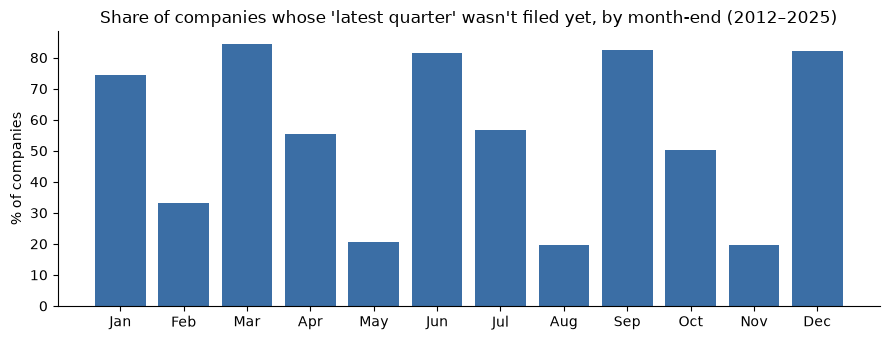

In [5]:
by_month = leak.groupby(leak.index.month)["leak"].mean()
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(by_month.index, by_month * 100, color="#3b6ea5")
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                             "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylabel("% of companies")
ax.set_title("Share of companies whose 'latest quarter' wasn't filed yet, by month-end (2012–2025)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

At quarter-ends roughly four in five companies are ahead by a quarter that won't be
filed for weeks. A month later about half still are, and two months later about one in
five. January and February run higher because the December quarter waits for the
10-K. Across all 5,300
companies in the full dataset the figure is 62%, and the
[look-ahead bias study](https://varvedata.com/look-ahead-bias.html) shows what it does
to factor rankings.

## The pattern: `merge_asof` on `filed`

Given any table of (company, date) rows (rebalance dates, trades, price observations),
attach the latest fundamentals that were public on that date.

In [6]:
def as_of(panel, fundamentals, cols, by="cik", on="date"):
    """attach to each panel row the latest fundamentals row filed on or before its date"""
    f = fundamentals.dropna(subset=["filed"]).sort_values("filed")
    out = pd.merge_asof(panel.sort_values(on), f[[by, "filed", "period_end"] + cols],
                        left_on=on, right_on="filed", by=by, direction="backward")
    return out.sort_values([by, on])


# a monthly panel for three companies
panel = pd.MultiIndex.from_product(
    [[320193, 789019, 1045810], pd.date_range("2024-07-31", "2025-02-28", freq="ME")],
    names=["cik", "date"]).to_frame(index=False)

as_of(panel, q, ["revenue", "eps_diluted"]).query("cik == 320193")

,cik,date,filed,period_end,revenue,eps_diluted
0,320193,2024-07-31,2024-05-03,2024-03-31,9.075300e+10,1.530000
3,320193,2024-08-31,2024-08-02,2024-06-30,8.577700e+10,1.400000
6,320193,2024-09-30,2024-08-02,2024-06-30,8.577700e+10,1.400000
11,320193,2024-10-31,2024-08-02,2024-06-30,8.577700e+10,1.400000
13,320193,2024-11-30,2024-11-01,2024-09-30,9.493000e+10,0.966748
16,320193,2024-12-31,2024-11-01,2024-09-30,9.493000e+10,0.966748
20,320193,2025-01-31,2025-01-31,2024-12-31,1.243000e+11,2.400000
22,320193,2025-02-28,2025-01-31,2024-12-31,1.243000e+11,2.400000


Each month gets the latest quarter Apple had filed by then. Look at 31 January 2025:
Apple filed that quarter the same day, which leads to the first of two details that
matter in practice:

* **Same-day trading.** A 10-Q filed after the close on day D can't be traded on day D's
  close. If you trade at the close, require `filed < date`
  (`allow_exact_matches=False`). Varve Events has each filing's exact acceptance time,
  to the second, if you need better.
* **Restatements.** The sample has each figure as first reported. The full dataset also
  has `value_latest` and a `fact_versions` table with every later restatement and its
  `known_from` date, so you can rebuild exactly what was known on any day. About 10% of
  first-reported revenue and net income figures change later.

## Next

**03 · Identifiers and delistings**: the other half of an honest backtest.